In [1]:
# 1. Configuração do Ambiente e Carregamento dos Dados Limpos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
import os
import sys

sys.path.append('..')
from src.metricas import ORDEM_GRAVIDADE, base_comparavel, comparar_dias, razao_letalidade, tabela_letalidade

# Configuração estética dos gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'


def virgula(valor, casas=1):
    """Formata um número com vírgula decimal nos rótulos dos gráficos."""
    return f'{valor:,.{casas}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


def carimbar(fig=None, y=-0.03):
    """Registra a data de corte dos dados na figura."""
    (fig or plt.gcf()).text(0.99, y, f"Dados até {df['data'].max():%d/%m/%Y}", ha='right', fontsize=8, color='#555555')

# Criar pasta de gráficos caso não exista
os.makedirs('../output/graficos', exist_ok=True)

# Carregamento do dataset limpo
df = pd.read_csv('../data/matao_limpo.csv', parse_dates=['data'])

print("--- Ambiente de Análise Pronto ---")
print(f"Dataset carregado: {df.shape[0]} linhas e {df.shape[1]} colunas.")
print(f"Período de análise: {df['data'].dt.year.min()} a {df['data'].dt.year.max()}")
print("\nPrimeiras 2 linhas:")
df.head(2)


--- Ambiente de Análise Pronto ---
Dataset carregado: 4126 linhas e 31 colunas.
Período de análise: 2015 a 2026

Primeiras 2 linhas:


,id_sinistro,tipo_registro,data,ano,mes,dia,hora,dia_semana,turno,tipo_via,...,qtd_outros_veiculos,mortos,feridos_graves,feridos_leves,ilesos,hora_int,total_vitimas,total_veiculos,gravidade,fim_de_semana
0,2456467,SINISTRO FATAL,2015-03-18,2015,3,18,18:05,Quarta-feira,NOITE,VIAS URBANAS,...,0,1,0,0,0,18.0,1,2,Com óbito,False
1,2456417,SINISTRO FATAL,2015-03-19,2015,3,19,21:53,Quinta-feira,NOITE,VIAS URBANAS,...,1,1,0,0,0,21.0,1,1,Com óbito,False


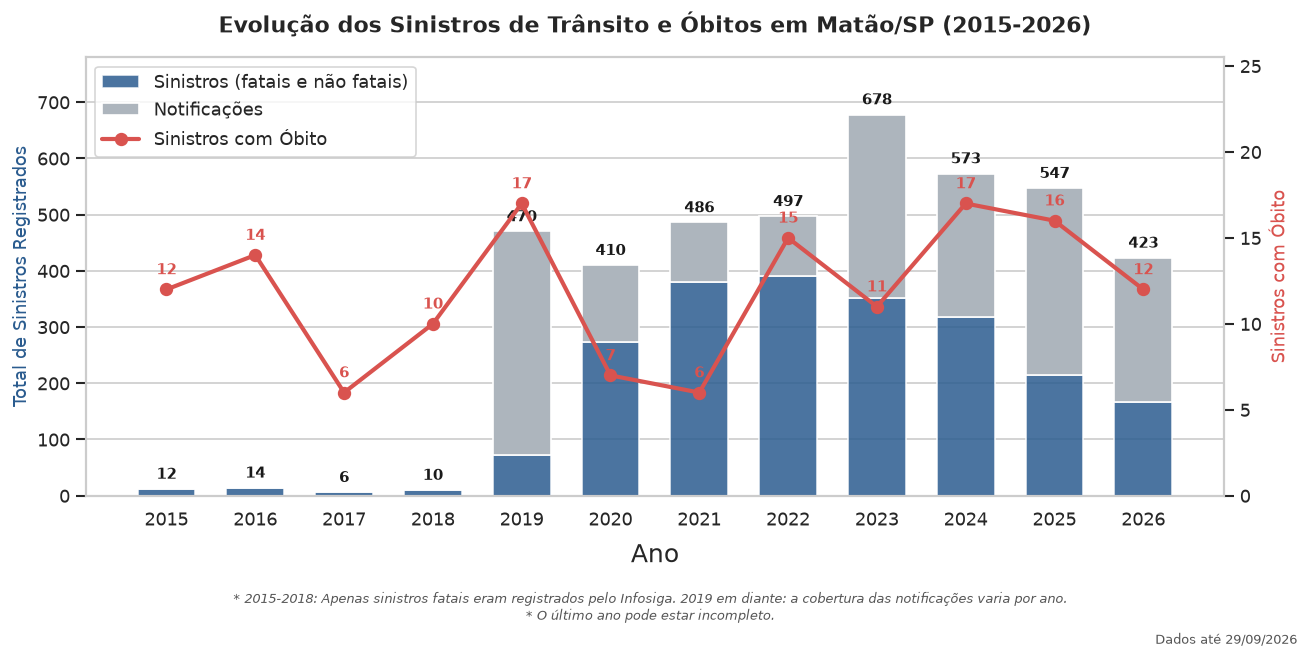

,ano,total_sinistros,notificacoes,sinistros_fatais
0,2015,12,0,12
1,2016,14,0,14
2,2017,6,0,6
3,2018,10,0,10
4,2019,470,397,17
5,2020,410,137,7
6,2021,486,105,6
7,2022,497,106,15
8,2023,678,326,11
9,2024,573,255,17


In [2]:
# 5.1 (A): Evolução Anual dos Sinistros e Fatalidades

# Agrupando os dados por ano: Total de Sinistros e Total de Fatais
dados_ano = df.groupby('ano').agg(
    total_sinistros=('id_sinistro', 'count'),
    notificacoes=('tipo_registro', lambda x: (x == 'NOTIFICACAO').sum()),
    sinistros_fatais=('mortos', lambda x: (x > 0).sum())
).reset_index()

fig, ax1 = plt.subplots(figsize=(11, 5))

# Cores
cor_barras = '#2b5c8f'
cor_linha = '#d9534f'

# 1. Gráfico de Barras: Total de Sinistros
ax1.bar(
    dados_ano['ano'], 
    dados_ano['total_sinistros'] - dados_ano['notificacoes'], 
    color=cor_barras, 
    alpha=0.85, 
    label='Sinistros (fatais e não fatais)', 
    width=0.65
)
barras = ax1.bar(
    dados_ano['ano'], 
    dados_ano['notificacoes'], 
    bottom=dados_ano['total_sinistros'] - dados_ano['notificacoes'], 
    color='#adb5bd', 
    label='Notificações', 
    width=0.65
)

# Adicionar rótulos numéricos no topo de cada barra
for barra in barras:
    altura = barra.get_y() + barra.get_height()
    ax1.annotate(
        f'{int(altura)}',
        xy=(barra.get_x() + barra.get_width() / 2, altura),
        xytext=(0, 4),
        textcoords="offset points",
        ha='center', va='bottom', fontsize=9, fontweight='bold', color='#1a1a1a'
    )

# 2. Linha com Marcadores: Sinistros com Vítimas Fatais
ax2 = ax1.twinx()  # Eixo secundário à direita
linha = ax2.plot(
    dados_ano['ano'], 
    dados_ano['sinistros_fatais'], 
    color=cor_linha, 
    marker='o', 
    linewidth=2.5, 
    markersize=7, 
    label='Sinistros com Óbito'
)

# Rótulos na linha de óbitos
for x, y in zip(dados_ano['ano'], dados_ano['sinistros_fatais']):
    ax2.annotate(
        f'{int(y)}',
        xy=(x, y),
        xytext=(0, 7),
        textcoords="offset points",
        ha='center', va='bottom', fontsize=9, fontweight='bold', color=cor_linha
    )

# Configurações dos eixos e títulos
ax1.set_title(f'Evolução dos Sinistros de Trânsito e Óbitos em Matão/SP ({df['ano'].min()}-{df['ano'].max()})', fontsize=13, fontweight='bold', pad=15)
ax1.set_xlabel('Ano', fontsize=15, labelpad=8)
ax1.set_ylabel('Total de Sinistros Registrados', fontsize=11, color=cor_barras)
ax2.set_ylabel('Sinistros com Óbito', fontsize=11, color=cor_linha)

# Ajustes de limites e ticks
ax1.set_xticks(dados_ano['ano'])
ax1.set_ylim(0, dados_ano['total_sinistros'].max() * 1.15)
ax2.set_ylim(0, dados_ano['sinistros_fatais'].max() * 1.5)
ax1.grid(axis='x')
ax2.grid(False)  # Evitar sobreposição de grades

# Legenda combinada
linhas, rotulos = ax1.get_legend_handles_labels()
linhas2, rotulos2 = ax2.get_legend_handles_labels()
ax1.legend(linhas + linhas2, rotulos + rotulos2, loc='upper left', frameon=True)

# Nota explicativa metodológica no rodapé do gráfico
plt.figtext(
    0.5, -0.05, 
    "* 2015-2018: Apenas sinistros fatais eram registrados pelo Infosiga. 2019 em diante: a cobertura das notificações varia por ano.\n* O último ano pode estar incompleto.", 
    ha="center", fontsize=8, style='italic', color='#555555'
)

plt.tight_layout()
carimbar(y=-0.09)
plt.savefig('../output/graficos/acidentes_por_ano.png', dpi=200, bbox_inches='tight')
plt.show()

# Resumo numérico complementar
dados_ano


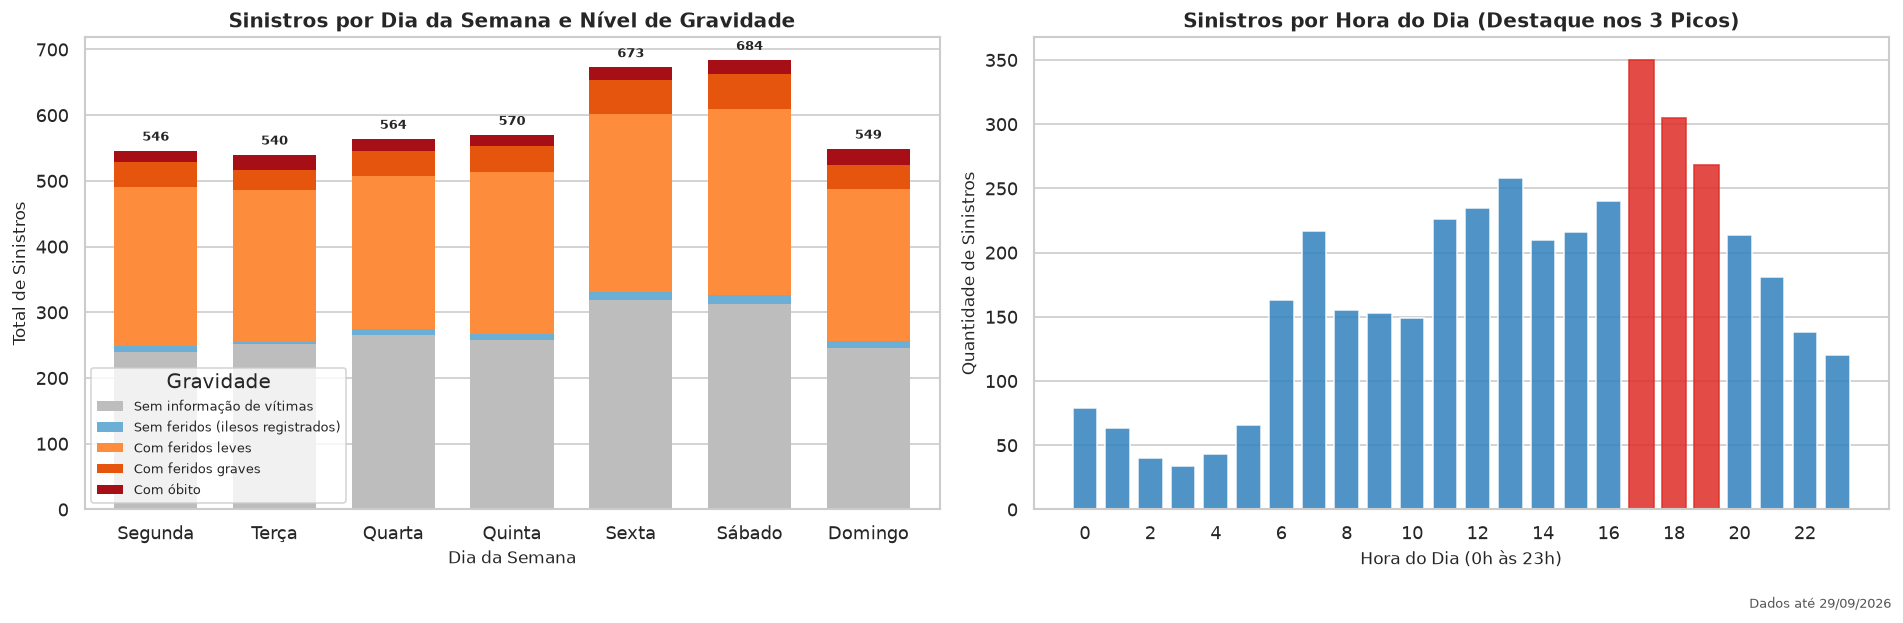

--- Top 5 Horários com Mais Registros em Matão ---
 -> 17:00h: 350 acidentes
 -> 18:00h: 305 acidentes
 -> 19:00h: 268 acidentes
 -> 13:00h: 258 acidentes
 -> 16:00h: 240 acidentes


In [3]:
# 5.1 (B): Padrões de Dia da Semana e Horário do Dia

# 1. Definir a ordem cronológica correta dos dias da semana
dias_ordenados = [
    'Segunda-feira', 'Terça-feira', 'Quarta-feira', 
    'Quinta-feira', 'Sexta-feira', 'Sábado', 'Domingo'
]

# --- GRÁFICO 1: Acidentes por Dia da Semana e Gravidade ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Tabela cruzada: Dia da semana x Gravidade
ordem_gravidade = ORDEM_GRAVIDADE[::-1]
crosstab_dias = pd.crosstab(df['dia_semana'], df['gravidade']).reindex(index=dias_ordenados, columns=ordem_gravidade)

# Cores: cinza (sem informação), azul (ilesos), amarelo (leves), laranja (graves), vermelho (óbitos)
paleta_gravidade = ['#bdbdbd', '#6baed6', '#fd8d3c', '#e6550d', '#a50f15']

crosstab_dias.plot(
    kind='bar', 
    stacked=True, 
    ax=axes[0], 
    color=paleta_gravidade, 
    edgecolor='none', 
    width=0.7
)

axes[0].set_title('Sinistros por Dia da Semana e Nível de Gravidade', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Dia da Semana', fontsize=10)
axes[0].set_ylabel('Total de Sinistros', fontsize=10)
axes[0].set_xticklabels([d.replace('-feira', '') for d in dias_ordenados], rotation=0)
axes[0].legend(title='Gravidade', frameon=True, fontsize=8)
axes[0].grid(axis='x')

# Adicionar total geral acima de cada barra do dia
totais_dias = crosstab_dias.sum(axis=1)
for i, total in enumerate(totais_dias):
    axes[0].annotate(
        f'{total}', 
        xy=(i, total), 
        xytext=(0, 4), 
        textcoords="offset points", 
        ha='center', va='bottom', fontsize=8, fontweight='bold'
    )


# --- GRÁFICO 2: Distribuição por Hora do Dia ---
df_hora_valida = df.dropna(subset=['hora_int']).copy()
contagem_horas = df_hora_valida['hora_int'].value_counts().reindex(range(24), fill_value=0)

barras_hora = axes[1].bar(
    contagem_horas.index, 
    contagem_horas.values, 
    color='#3182bd', 
    alpha=0.85, 
    width=0.75
)

# Destacar os 3 horários de pico com cor diferente (vermelho escuro)
top_3_horas = contagem_horas.nlargest(3).index
for hora, barra in zip(contagem_horas.index, barras_hora):
    if hora in top_3_horas:
        barra.set_color('#de2d26')

axes[1].set_title('Sinistros por Hora do Dia (Destaque nos 3 Picos)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Hora do Dia (0h às 23h)', fontsize=10)
axes[1].set_ylabel('Quantidade de Sinistros', fontsize=10)
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(axis='x')

plt.tight_layout()
carimbar(y=-0.03)
plt.savefig('../output/graficos/acidentes_dia_e_hora.png', dpi=150, bbox_inches='tight')
plt.show()

# Exibir os 5 horários com maior volume
print("--- Top 5 Horários com Mais Registros em Matão ---")
for h, qtd in contagem_horas.nlargest(5).items():
    print(f" -> {int(h):02d}:00h: {qtd} acidentes")


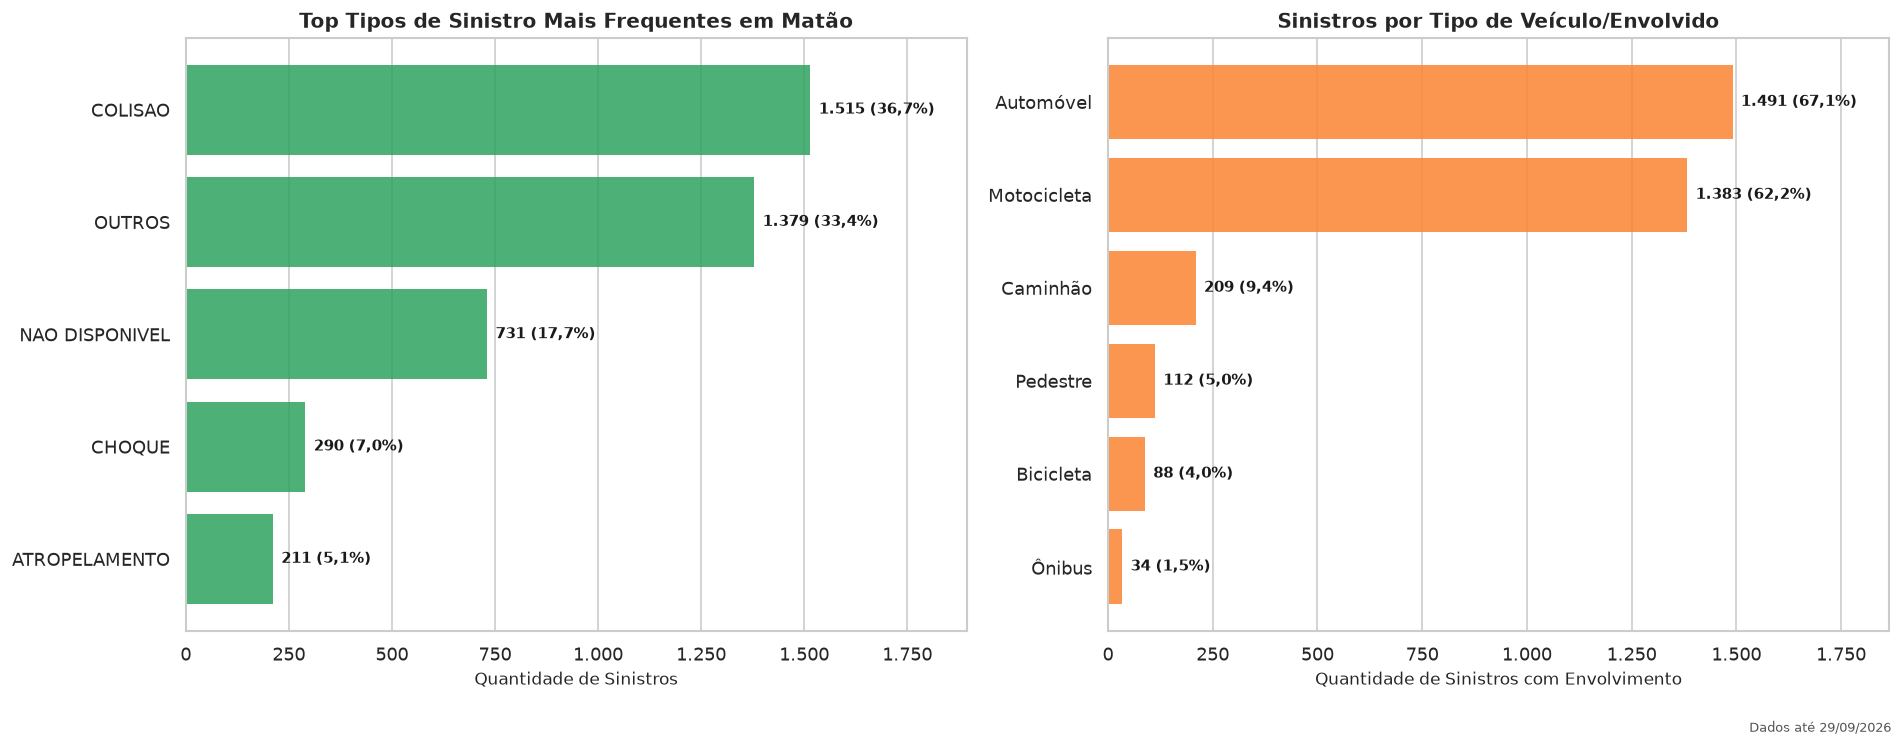

--- Envolvimento por Modal em Matão ---
 -> Automóvel: presente em 1491 acidentes (67.1%)
 -> Motocicleta: presente em 1383 acidentes (62.2%)
 -> Caminhão: presente em 209 acidentes (9.4%)
 -> Pedestre: presente em 112 acidentes (5.0%)
 -> Bicicleta: presente em 88 acidentes (4.0%)
 -> Ônibus: presente em 34 acidentes (1.5%)


In [4]:
# 5.2: Tipos de Sinistros e Modais Mais Envolvidos

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- GRÁFICO 1: Tipos de Sinistros Mais Frequentes ---
contagem_tipos = df['tipo_sinistro'].value_counts()
top_tipos = contagem_tipos.head(8).sort_values(ascending=True)

barras_tipos = axes[0].barh(
    top_tipos.index, 
    top_tipos.values, 
    color='#2ca25f', 
    alpha=0.85, 
    edgecolor='none'
)

# Adicionar rótulos de contagem e percentual em cada barra horizontal
total_sinistros = len(df)
for barra in barras_tipos:
    largura = barra.get_width()
    pct = (largura / total_sinistros) * 100
    axes[0].annotate(
        f'{virgula(largura, 0)} ({virgula(pct)}%)', 
        xy=(largura, barra.get_y() + barra.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        ha='left', va='center', fontsize=9, fontweight='bold', color='#1a1a1a'
    )

axes[0].set_title('Top Tipos de Sinistro Mais Frequentes em Matão', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Quantidade de Sinistros', fontsize=10)
axes[0].set_xlim(0, top_tipos.max() * 1.25)
axes[0].grid(axis='y')


# --- GRÁFICO 2: Presença dos Modais nos Sinistros ---
# Contamos em quantos registros com modal informado houve pelo menos 1 veículo/pedestre da categoria
df_modal = df[(df['total_veiculos'] > 0) | (df['qtd_pedestre'] > 0)]
modais = {
    'Automóvel': (df_modal['qtd_automovel'] > 0).sum(),
    'Motocicleta': (df_modal['qtd_motocicleta'] > 0).sum(),
    'Caminhão': (df_modal['qtd_caminhao'] > 0).sum(),
    'Pedestre': (df_modal['qtd_pedestre'] > 0).sum(),
    'Bicicleta': (df_modal['qtd_bicicleta'] > 0).sum(),
    'Ônibus': (df_modal['qtd_onibus'] > 0).sum()
}
serie_modais = pd.Series(modais).sort_values(ascending=True)

total_com_modal = len(df_modal)
barras_modais = axes[1].barh(
    serie_modais.index, 
    serie_modais.values, 
    color='#fa8431', 
    alpha=0.85, 
    edgecolor='none'
)

for barra in barras_modais:
    largura = barra.get_width()
    pct = (largura / total_com_modal) * 100
    axes[1].annotate(
        f'{virgula(largura, 0)} ({virgula(pct)}%)', 
        xy=(largura, barra.get_y() + barra.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        ha='left', va='center', fontsize=9, fontweight='bold', color='#1a1a1a'
    )

axes[1].set_title('Sinistros por Tipo de Veículo/Envolvido', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Quantidade de Sinistros com Envolvimento', fontsize=10)
axes[1].set_xlim(0, serie_modais.max() * 1.25)
axes[1].grid(axis='y')

for eixo in axes:
    eixo.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: virgula(valor, 0)))

plt.tight_layout()
carimbar(y=-0.03)
plt.savefig('../output/graficos/tipos_e_veiculos.png', dpi=150, bbox_inches='tight')
plt.show()

# Resumo numérico do ranking dos modais
print("--- Envolvimento por Modal em Matão ---")
for modal, qtd in serie_modais.sort_values(ascending=False).items():
    print(f" -> {modal}: presente em {qtd} acidentes ({(qtd/total_com_modal)*100:.1f}%)")


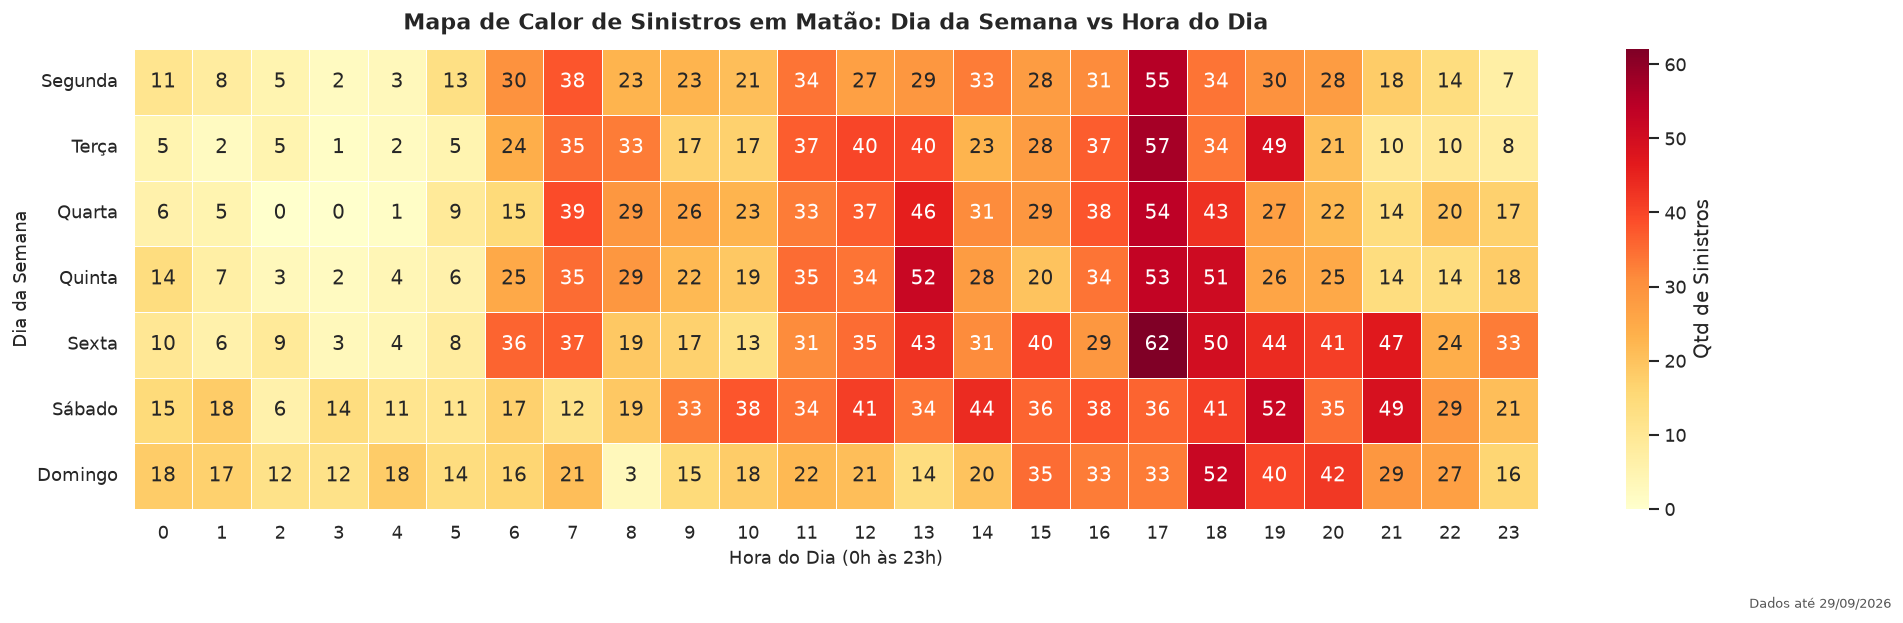

--- Letalidade por tipo de sinistro (base comparável) ---
 tipo_sinistro  sinistros  sinistros_fatais  mortos  feridos_graves  letalidade_pct
 ATROPELAMENTO         92                14      14              24           15.22
        CHOQUE        267                32      33              36           11.99
        OUTROS        371                17      18              47            4.58
       COLISAO       1360                38      40             182            2.79
NAO DISPONIVEL         78                 0       0               5            0.00

--- Choque vs colisão por tipo de via ---
           tipo_via tipo_sinistro  sinistros  sinistros_fatais  mortos  feridos_graves  letalidade_pct
ESTRADAS E RODOVIAS       COLISAO        112                16      17              22           14.29
ESTRADAS E RODOVIAS        CHOQUE         59                 8       8              10           13.56
       VIAS URBANAS        CHOQUE        207                23      24              26

In [5]:
# 5.3: Cruzamento de Variáveis - Heatmap Dia x Hora e Matriz de Gravidade

dias_ordenados = [
    'Segunda-feira', 'Terça-feira', 'Quarta-feira', 
    'Quinta-feira', 'Sexta-feira', 'Sábado', 'Domingo'
]

# --- 1. HEATMAP: Dia da Semana vs Hora do Dia ---
df_hora_valida = df.dropna(subset=['hora_int']).copy()
df_hora_valida['hora_int'] = df_hora_valida['hora_int'].astype(int)

heatmap_dia_hora = df_hora_valida.pivot_table(
    index='dia_semana', 
    columns='hora_int', 
    values='id_sinistro', 
    aggfunc='count', 
    fill_value=0
).reindex(dias_ordenados)

plt.figure(figsize=(16, 5))
sns.heatmap(
    heatmap_dia_hora, 
    cmap='YlOrRd', 
    linewidths=0.5, 
    annot=True, 
    fmt='d', 
    cbar_kws={'label': 'Qtd de Sinistros'}
)
plt.title('Mapa de Calor de Sinistros em Matão: Dia da Semana vs Hora do Dia', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Hora do Dia (0h às 23h)', fontsize=11)
plt.ylabel('Dia da Semana', fontsize=11)
plt.yticks([i + 0.5 for i in range(7)], [d.replace('-feira', '') for d in dias_ordenados], rotation=0)

plt.tight_layout()
carimbar(y=-0.03)
plt.savefig('../output/graficos/heatmap_dia_hora.png', dpi=150, bbox_inches='tight')
plt.show()


# --- 2. LETALIDADE: sinistros de 2019 em diante, sem notificações ---
df_comparavel = base_comparavel(df)
print("--- Letalidade por tipo de sinistro (base comparável) ---")
print(tabela_letalidade(df_comparavel).to_string(index=False))

print("\n--- Choque vs colisão por tipo de via ---")
comparacao = df_comparavel[df_comparavel['tipo_sinistro'].isin(['CHOQUE', 'COLISAO']) & (df_comparavel['tipo_via'] != 'NAO DISPONIVEL')]
print(tabela_letalidade(comparacao, por=['tipo_via', 'tipo_sinistro']).to_string(index=False))

razao, ic_inf, ic_sup = razao_letalidade(df_comparavel, 'CHOQUE', 'COLISAO')
print(f"\nRazão de letalidade choque/colisão: {razao:.2f} (IC95% {ic_inf:.2f} a {ic_sup:.2f})")

print("\n--- Gravidade com e sem motocicleta, por via (% da base comparável) ---")
perfil = df_comparavel.assign(
    com_moto=df_comparavel['qtd_motocicleta'] > 0,
    grave_ou_fatal=(df_comparavel['mortos'] > 0) | (df_comparavel['feridos_graves'] > 0),
)
perfil = perfil[perfil['tipo_via'] != 'NAO DISPONIVEL']
print(perfil.groupby(['tipo_via', 'com_moto']).agg(sinistros=('id_sinistro', 'count'), grave_ou_fatal_pct=('grave_ou_fatal', lambda s: round(s.mean() * 100, 1))).to_string())

print("\n--- Registros entre 22h e 5h (2019 em diante) ---")
recente = df[df['ano'] >= 2019]
noite = recente['hora_int'].isin([22, 23, 0, 1, 2, 3, 4, 5])
print(noite.groupby(recente['fim_de_semana']).mean().mul(100).round(1).to_string())


In [6]:
# 7.1: Comparação de registros diários entre dias úteis e fins de semana

# Cada dia do calendário conta, inclusive os dias sem nenhum registro
teste = comparar_dias(df[df['ano'] >= 2019])

print("--- Médias Diárias de Registros (2019 em diante) ---")
print(f"Dias úteis:      {teste['media_uteis']:.2f} registros/dia")
print(f"Fins de semana:  {teste['media_fds']:.2f} registros/dia")
print(f"Dias sem registro: {teste['dias_sem_registro_pct']:.1f}%")

print("\n--- Teste de Welch ---")
print(f"Diferença: {teste['diferenca']:.3f} (IC95% {teste['ic95'][0]:.3f} a {teste['ic95'][1]:.3f})")
print(f"p-valor:   {teste['p_welch']:.3f}")

print("\n--- Média por dia da semana (0 = segunda) ---")
print(teste['media_por_dia'].round(2).to_string())


--- Médias Diárias de Registros (2019 em diante) ---
Dias úteis:      1.42 registros/dia
Fins de semana:  1.51 registros/dia
Dias sem registro: 29.1%

--- Teste de Welch ---
Diferença: 0.093 (IC95% -0.020 a 0.205)
p-valor:   0.107

--- Média por dia da semana (0 = segunda) ---
0    1.34
1    1.32
2    1.38
3    1.39
4    1.66
5    1.68
6    1.34


Dados de Treino: 1515 amostras
Dados de Teste:  650 amostras



--- Relatório de Classificação (Conjunto de Teste) ---
                                  precision    recall  f1-score   support

              Com feridos graves       0.00      0.00      0.00        84
               Com feridos leves       0.79      1.00      0.88       512
                       Com óbito       0.00      0.00      0.00        29
Sem feridos (ilesos registrados)       0.00      0.00      0.00        19
       Sem informação de vítimas       0.00      0.00      0.00         6

                        accuracy                           0.79       650
                       macro avg       0.16      0.20      0.18       650
                    weighted avg       0.62      0.79      0.69       650

Acurácia: 0.788
Sempre prever a classe mais comum: 0.788
Acurácia balanceada: 0.200


tipo_sinistro_OUTROS            0.0013
tipo_sinistro_NAO DISPONIVEL    0.0015
qtd_caminhao                    0.0020
mes                             0.0028
tipo_sinistro_COLISAO           0.0030
qtd_pedestre                    0.0064
tipo_sinistro_CHOQUE            0.0064
qtd_automovel                   0.0135
tipo_via_VIAS URBANAS           0.0139
qtd_motocicleta                 0.0203


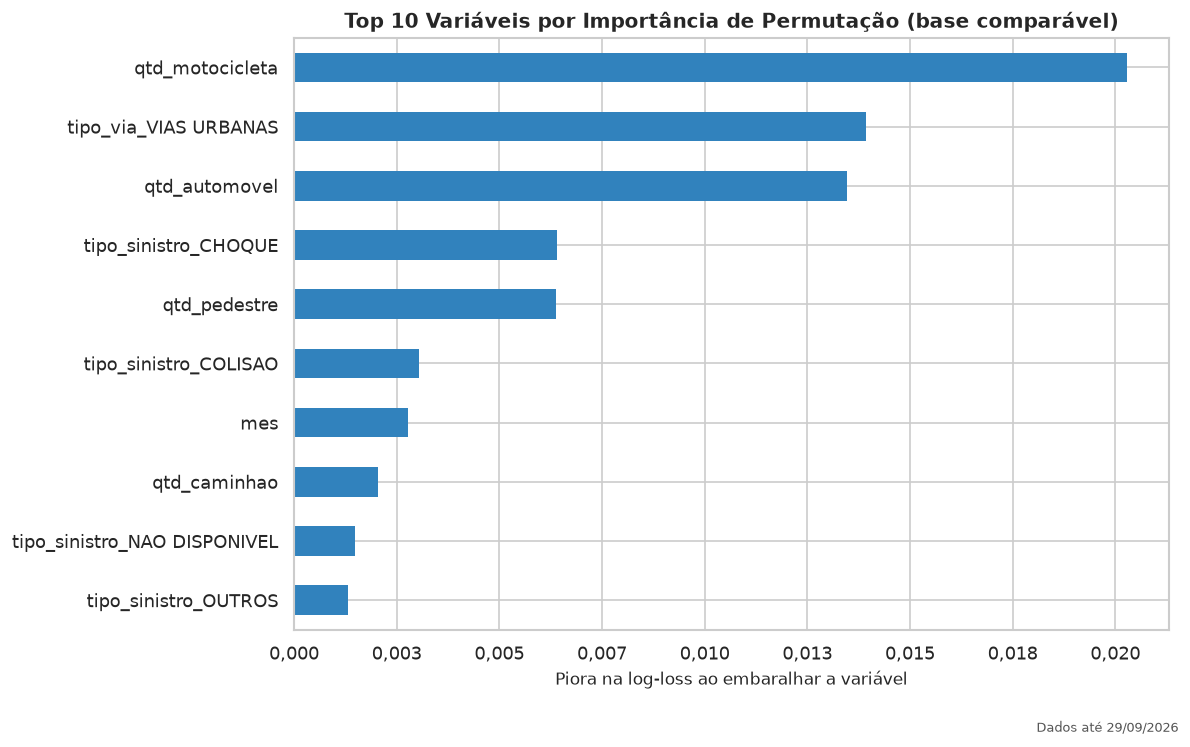

In [7]:
# 7.2: Modelo Preditivo de Machine Learning (Random Forest Classifier)

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Seleção das Features (variáveis preditoras) e Target (alvo)
features_categoricas = ['tipo_sinistro', 'tipo_via', 'dia_semana', 'turno']
features_numericas = [
    'hora_int', 'mes', 'qtd_motocicleta', 
    'qtd_automovel', 'qtd_caminhao', 'qtd_pedestre', 'qtd_bicicleta'
]

# Filtrar registros sem valores nulos nas features
df_ml = base_comparavel(df)[features_categoricas + features_numericas + ['gravidade']].dropna().copy()
# Classes com poucos casos impedem a divisão estratificada
df_ml = df_ml[df_ml['gravidade'].map(df_ml['gravidade'].value_counts()) >= 10]

# 2. Pré-processamento: One-Hot Encoding nas variáveis categóricas
X = pd.get_dummies(df_ml[features_categoricas + features_numericas], columns=features_categoricas, drop_first=True)
y = df_ml['gravidade']

# 3. Divisão Treino e Teste (70% treino, 30% teste) com estratificação
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.30, 
    random_state=42, 
    stratify=y
)

print(f"Dados de Treino: {X_train.shape[0]} amostras")
print(f"Dados de Teste:  {X_test.shape[0]} amostras")

# 4. Treinamento sem class_weight, para que predict_proba reflita a frequência das classes
clf = RandomForestClassifier(
    n_estimators=150, 
    max_depth=10, 
    min_samples_leaf=5, 
    random_state=42
)
clf.fit(X_train, y_train)

# 5. Avaliação do Modelo no Conjunto de Teste
y_pred = clf.predict(X_test)

print("\n--- Relatório de Classificação (Conjunto de Teste) ---")
print(classification_report(y_test, y_pred, zero_division=0))

print(f"Acurácia: {accuracy_score(y_test, y_pred):.3f}")
print(f"Sempre prever a classe mais comum: {y_test.value_counts(normalize=True).max():.3f}")
print(f"Acurácia balanceada: {balanced_accuracy_score(y_test, y_pred):.3f}")

# 6. Importância de permutação no conjunto de teste (não indica sentido nem causa)
permutacao = permutation_importance(clf, X_test, y_test, n_repeats=15, random_state=42, scoring='neg_log_loss')
importancias = pd.Series(permutacao.importances_mean, index=X.columns).sort_values(ascending=True)
print(importancias.tail(10).round(4).to_string())

plt.figure(figsize=(10, 6))
importancias.tail(10).plot(kind='barh', color='#3182bd', edgecolor='none')
plt.title('Top 10 Variáveis por Importância de Permutação (base comparável)', fontsize=12, fontweight='bold')
plt.xlabel('Piora na log-loss ao embaralhar a variável', fontsize=10)
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda valor, _: virgula(valor, 3)))
plt.tight_layout()
carimbar(y=-0.03)
plt.savefig('../output/graficos/importancia_features_ml.png', dpi=150, bbox_inches='tight')
plt.show()
